In [57]:
files_to_check = [

    MODELS_DIR /
    "autoencoder_encoder.keras",

    MODELS_DIR /
    "autoencoder_decoder.keras",

    MODELS_DIR /
    "autoencoder_final.keras",

    MODELS_DIR /
    "autoencoder_latent_scaler.joblib",

    SYNTHETIC_DIR /
    "autoencoder_fraud_synthetic.parquet",

    PROCESSED_DIR /
    "X_train_autoencoder.parquet",

    PROCESSED_DIR /
    "y_train_autoencoder.parquet",

    METRICS_DIR /
    "autoencoder_summary.csv",

    METRICS_DIR /
    "autoencoder_feature_fidelity.csv",

    FIGURES_DIR /
    "autoencoder_training_loss.png",

    FIGURES_DIR /
    "autoencoder_reconstruction_errors.png",

    FIGURES_DIR /
    "autoencoder_pca_real_vs_synthetic.png"
]

for file in files_to_check:
    print(
        file.name,
        "→",
        file.exists()
    )

autoencoder_encoder.keras → True
autoencoder_decoder.keras → True
autoencoder_final.keras → True
autoencoder_latent_scaler.joblib → True
autoencoder_fraud_synthetic.parquet → True
X_train_autoencoder.parquet → True
y_train_autoencoder.parquet → True
autoencoder_summary.csv → True
autoencoder_feature_fidelity.csv → True
autoencoder_training_loss.png → True
autoencoder_reconstruction_errors.png → True
autoencoder_pca_real_vs_synthetic.png → True


In [55]:
ae_summary = pd.DataFrame({
    "Mesure": [
        "Fraudes réelles utilisées",
        "Dimension latente",
        "Meilleure époque",
        "Fraudes synthétiques créées",
        "NaN synthétiques",
        "Inf synthétiques",
        "Doublons synthétiques",
        "Copies exactes",
        "MSE reconstruction",
        "Diversité réelle",
        "Diversité synthétique",
        "Ratio diversité AE/Réel",
        "Erreur corrélation Spearman",
        "Médiane réel→réel",
        "Médiane AE→réel",
        "Valeurs hors min/max (%)"
    ],

    "Valeur": [
        len(X_real_fraud),
        BEST_LATENT_DIM,
        BEST_EPOCH,
        len(X_ae_synthetic),
        ae_nan_count,
        ae_inf_count,
        ae_duplicate_count,
        ae_exact_copies,
        mse_after_final,
        real_diversity,
        ae_diversity,
        ae_diversity_ratio,
        ae_spearman_error,
        median_real_real,
        median_ae_real,
        ae_outside_pct
    ]
})

display(ae_summary)

ae_summary.to_csv(
    METRICS_DIR /
    "autoencoder_summary.csv",
    index=False
)

,Mesure,Valeur
0,Fraudes réelles utilisées,331.000000
1,Dimension latente,12.000000
2,Meilleure époque,500.000000
3,Fraudes synthétiques créées,197946.000000
4,NaN synthétiques,0.000000
5,Inf synthétiques,0.000000
6,Doublons synthétiques,11.000000
7,Copies exactes,0.000000
8,MSE reconstruction,0.002311
9,Diversité réelle,0.926864


In [54]:
best_history_df = pd.DataFrame(
    best_history
)

best_history_df.to_csv(
    METRICS_DIR /
    "autoencoder_training_history.csv",
    index=False
)

In [53]:
encoder.save(
    MODELS_DIR /
    "autoencoder_encoder.keras"
)

decoder.save(
    MODELS_DIR /
    "autoencoder_decoder.keras"
)

autoencoder.save(
    MODELS_DIR /
    "autoencoder_final.keras"
)

joblib.dump(
    latent_scaler,
    MODELS_DIR /
    "autoencoder_latent_scaler.joblib"
)

X_ae_synthetic.to_parquet(
    SYNTHETIC_DIR /
    "autoencoder_fraud_synthetic.parquet",
    index=False
)

X_train_ae.to_parquet(
    PROCESSED_DIR /
    "X_train_autoencoder.parquet",
    index=False
)

y_train_ae.to_frame().to_parquet(
    PROCESSED_DIR /
    "y_train_autoencoder.parquet",
    index=False
)

latent_results_df.to_csv(
    METRICS_DIR /
    "autoencoder_latent_dimension_comparison.csv",
    index=False
)

ae_fidelity_df.to_csv(
    METRICS_DIR /
    "autoencoder_feature_fidelity.csv",
    index=False
)

In [52]:
y_ae_synthetic = pd.Series(
    np.ones(
        len(X_ae_synthetic),
        dtype=np.int8
    ),
    name=y_train.name
)

X_train_ae = pd.concat(
    [
        X_train.reset_index(drop=True),
        X_ae_synthetic
    ],
    ignore_index=True
)

y_train_ae = pd.concat(
    [
        y_train.reset_index(drop=True),
        y_ae_synthetic
    ],
    ignore_index=True
)

print(
    "X_train_ae :",
    X_train_ae.shape
)

print(
    "\nDistribution :"
)

print(
    y_train_ae.value_counts()
)

X_train_ae : (396554, 30)

Distribution :
Class
0    198277
1    198277
Name: count, dtype: int64


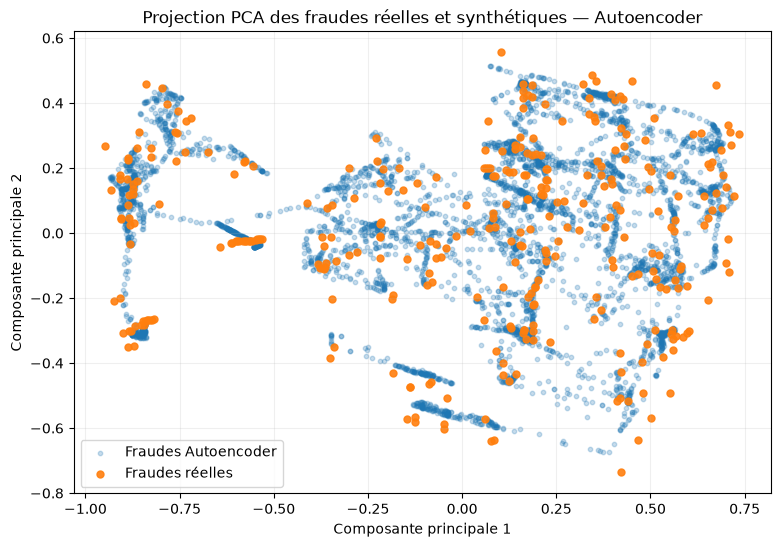

In [51]:
ae_vis = X_ae_synthetic.sample(
    n=min(
        5000,
        len(X_ae_synthetic)
    ),
    random_state=SEED
)

pca_ae = PCA(
    n_components=2
)

real_pca = pca_ae.fit_transform(
    X_real_fraud
)

ae_pca = pca_ae.transform(
    ae_vis
)

fig = plt.figure(
    figsize=(9, 6)
)

plt.scatter(
    ae_pca[:, 0],
    ae_pca[:, 1],
    alpha=0.25,
    s=10,
    label="Fraudes Autoencoder"
)

plt.scatter(
    real_pca[:, 0],
    real_pca[:, 1],
    alpha=0.9,
    s=25,
    label="Fraudes réelles"
)

plt.xlabel(
    "Composante principale 1"
)

plt.ylabel(
    "Composante principale 2"
)

plt.title(
    "Projection PCA des fraudes réelles et synthétiques — Autoencoder"
)

plt.legend()
plt.grid(alpha=0.2)

fig.savefig(
    FIGURES_DIR / "autoencoder_pca_real_vs_synthetic.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [50]:
real_corr = X_real_fraud.corr(
    method="spearman"
)

ae_corr = X_ae_synthetic.corr(
    method="spearman"
)

corr_diff = np.abs(
    real_corr.to_numpy()
    -
    ae_corr.to_numpy()
)

finite_mask = np.isfinite(
    corr_diff
)

ae_spearman_error = corr_diff[
    finite_mask
].mean()

print(
    "Erreur moyenne des corrélations de Spearman :",
    ae_spearman_error
)

Erreur moyenne des corrélations de Spearman : 0.1746540141921981


In [49]:
print(
    "KS moyen :",
    ae_fidelity_df[
        "KS_Statistic"
    ].mean()
)

print(
    "KS maximum :",
    ae_fidelity_df[
        "KS_Statistic"
    ].max()
)

print(
    "Wasserstein moyen :",
    ae_fidelity_df[
        "Wasserstein_Distance"
    ].mean()
)

KS moyen : 0.1381156465826496
KS maximum : 0.3116946386824714
Wasserstein moyen : 0.01656845472658271


In [48]:
ae_fidelity_rows = []

for feature in X_real_fraud.columns:

    real_values = X_real_fraud[
        feature
    ].to_numpy()

    synthetic_values = X_ae_synthetic[
        feature
    ].to_numpy()

    ks_stat, _ = ks_2samp(
        real_values,
        synthetic_values
    )

    wass = wasserstein_distance(
        real_values,
        synthetic_values
    )

    ae_fidelity_rows.append({
        "Feature": feature,
        "KS_Statistic": ks_stat,
        "Wasserstein_Distance": wass
    })

ae_fidelity_df = pd.DataFrame(
    ae_fidelity_rows
)

ae_fidelity_df = ae_fidelity_df.sort_values(
    "KS_Statistic",
    ascending=False
)

display(
    ae_fidelity_df.head(10)
)

,Feature,KS_Statistic,Wasserstein_Distance
13,V13,0.311695,0.059395
26,V26,0.276175,0.038179
25,V25,0.269027,0.020041
22,V22,0.246856,0.019801
15,V15,0.244097,0.044966
24,V24,0.230239,0.034094
1,V1,0.223545,0.015670
23,V23,0.220998,0.006786
21,V21,0.184968,0.007772
27,V27,0.160148,0.009936


In [47]:
ae_diversity_sample = X_ae_synthetic.sample(
    n=len(X_real_fraud),
    random_state=SEED
)

real_diversity = pdist(
    X_real_fraud.to_numpy()
).mean()

ae_diversity = pdist(
    ae_diversity_sample.to_numpy()
).mean()

ae_diversity_ratio = (
    ae_diversity
    /
    real_diversity
)

print(
    "Diversité réelle :",
    real_diversity
)

print(
    "Diversité synthétique :",
    ae_diversity
)

print(
    "Ratio AE/Réel :",
    ae_diversity_ratio
)

Diversité réelle : 0.926863647990703
Diversité synthétique : 0.8387150042226394
Ratio AE/Réel : 0.9048957805615139


In [46]:
ae_sample_nn = X_ae_synthetic.sample(
    n=min(
        5000,
        len(X_ae_synthetic)
    ),
    random_state=SEED
)

synth_distances, _ = nn_real.kneighbors(
    ae_sample_nn.to_numpy(),
    n_neighbors=1
)

ae_to_real = synth_distances[:, 0]

median_real_real = np.median(
    real_to_real
)

median_ae_real = np.median(
    ae_to_real
)

print(
    "Médiane distance réel→réel :",
    median_real_real
)

print(
    "Médiane distance AE→réel :",
    median_ae_real
)

Médiane distance réel→réel : 0.23246914530944554
Médiane distance AE→réel : 0.20484236939055003


In [45]:
nn_real = NearestNeighbors(
    n_neighbors=2,
    metric="euclidean"
)

nn_real.fit(
    X_real_fraud.to_numpy()
)

real_distances, _ = nn_real.kneighbors(
    X_real_fraud.to_numpy()
)

real_to_real = real_distances[:, 1]


In [44]:
real_min = X_real_fraud.min()
real_max = X_real_fraud.max()

outside_mask = (
    X_ae_synthetic.lt(real_min)
    |
    X_ae_synthetic.gt(real_max)
)

ae_outside_count = int(
    outside_mask.sum().sum()
)

ae_outside_pct = (
    100
    * ae_outside_count
    / X_ae_synthetic.size
)

print(
    "Valeurs hors min/max réel :",
    ae_outside_count
)

print(
    "Pourcentage :",
    ae_outside_pct,
    "%"
)

Valeurs hors min/max réel : 4610
Pourcentage : 0.07763059959113429 %


In [43]:
real_index = pd.MultiIndex.from_frame(
    X_real_fraud
)

synthetic_index = pd.MultiIndex.from_frame(
    X_ae_synthetic
)

ae_exact_copies = int(
    synthetic_index.isin(
        real_index
    ).sum()
)

print(
    "Copies exactes de fraudes réelles :",
    ae_exact_copies
)

Copies exactes de fraudes réelles : 0


In [42]:
ae_nan_count = int(
    X_ae_synthetic.isna().sum().sum()
)

ae_inf_count = int(
    np.isinf(
        X_ae_synthetic.to_numpy()
    ).sum()
)

ae_duplicate_count = int(
    X_ae_synthetic.duplicated().sum()
)

print("NaN :", ae_nan_count)
print("Infini :", ae_inf_count)
print(
    "Doublons exacts :",
    ae_duplicate_count
)

print(
    "Minimum généré :",
    X_ae_synthetic.min().min()
)

print(
    "Maximum généré :",
    X_ae_synthetic.max().max()
)

NaN : 0
Infini : 0
Doublons exacts : 11
Minimum généré : 0.0030106416
Maximum généré : 0.9762605


In [41]:
ae_synthetic_array = decoder.predict(
    Z_synthetic,
    batch_size=2048,
    verbose=1
)

X_ae_synthetic = pd.DataFrame(
    ae_synthetic_array,
    columns=X_real_fraud.columns
)

print(
    "Fraudes synthétiques Autoencoder :",
    X_ae_synthetic.shape
)

display(
    X_ae_synthetic.head()
)

97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
Fraudes synthétiques Autoencoder : (197946, 30)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
0,0.322420,0.910917,0.775498,0.706066,0.392700,0.446120,0.522046,0.519789,0.802979,0.411929,...,0.381876,0.585729,0.472784,0.585663,0.418511,0.531802,0.422900,0.660367,0.264850,0.441194
1,0.374553,0.916359,0.772184,0.716222,0.378019,0.448393,0.525733,0.531944,0.802260,0.418851,...,0.380272,0.583629,0.473790,0.586339,0.418209,0.530660,0.417091,0.658922,0.261567,0.535446
2,0.593236,0.430414,0.947504,0.057273,0.849926,0.179702,0.622296,0.105193,0.456377,0.088989,...,0.492931,0.292185,0.750527,0.662303,0.442849,0.455925,0.369890,0.477702,0.214411,0.018947
3,0.772325,0.956326,0.795416,0.679410,0.462868,0.534150,0.520297,0.574486,0.776846,0.405971,...,0.389021,0.553029,0.462597,0.594786,0.294102,0.558845,0.475402,0.663312,0.256868,0.016166
4,0.818281,0.907756,0.785609,0.645764,0.420426,0.437318,0.524780,0.513742,0.800045,0.377393,...,0.390410,0.575797,0.489344,0.590132,0.423895,0.519283,0.409672,0.645302,0.255874,0.559350


In [40]:
Z_synthetic = latent_scaler.inverse_transform(
    Z_synthetic_scaled
).astype(np.float32)

print(
    "Forme Z synthétique :",
    Z_synthetic.shape
)

Forme Z synthétique : (197946, 12)


In [39]:
rng = np.random.default_rng(SEED)

anchor_indices = rng.integers(
    0,
    len(Z_real_scaled),
    size=N_SYNTHETIC_AE
)

neighbor_positions = rng.integers(
    0,
    K_LATENT_NEIGHBORS,
    size=N_SYNTHETIC_AE
)

partner_indices = latent_neighbors[
    anchor_indices,
    neighbor_positions
]

alphas = rng.uniform(
    0.0,
    1.0,
    size=(N_SYNTHETIC_AE, 1)
).astype(np.float32)

Z_synthetic_scaled = (
    Z_real_scaled[anchor_indices]
    +
    alphas
    *
    (
        Z_real_scaled[partner_indices]
        -
        Z_real_scaled[anchor_indices]
    )
)

print(
    "Nouveaux points latents :",
    Z_synthetic_scaled.shape
)

Nouveaux points latents : (197946, 12)


In [38]:
n_normal = int(
    (y_train == 0).sum()
)

n_fraud = int(
    (y_train == 1).sum()
)

N_SYNTHETIC_AE = (
    n_normal - n_fraud
)

print(
    "Fraudes synthétiques à créer :",
    N_SYNTHETIC_AE
)


Fraudes synthétiques à créer : 197946


In [37]:
K_LATENT_NEIGHBORS = 5

latent_nn = NearestNeighbors(
    n_neighbors=K_LATENT_NEIGHBORS + 1,
    metric="euclidean"
)

latent_nn.fit(
    Z_real_scaled
)

latent_distances, latent_indices = latent_nn.kneighbors(
    Z_real_scaled
)

# Première colonne = le point lui-même.
latent_neighbors = latent_indices[:, 1:]

print(
    "Forme des voisins latents :",
    latent_neighbors.shape
)

Forme des voisins latents : (331, 5)


In [36]:
latent_scaler = StandardScaler()

Z_real_scaled = latent_scaler.fit_transform(
    Z_real
)

print(
    "Forme espace latent normalisé :",
    Z_real_scaled.shape
)

Forme espace latent normalisé : (331, 12)


In [35]:
Z_real = encoder.predict(
    fraud_array,
    verbose=0
)

print("Fraudes originales :", fraud_array.shape)
print("Représentations latentes :", Z_real.shape)

Fraudes originales : (331, 30)
Représentations latentes : (331, 12)


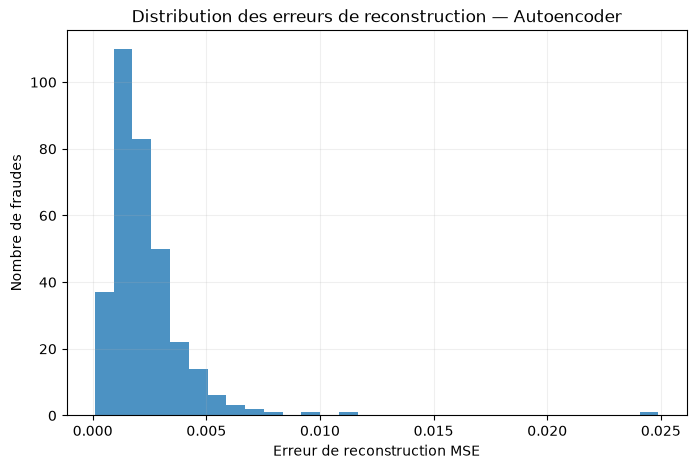

In [34]:
fig = plt.figure(figsize=(8, 5))

plt.hist(
    reconstruction_errors,
    bins=30,
    alpha=0.8
)

plt.xlabel("Erreur de reconstruction MSE")
plt.ylabel("Nombre de fraudes")
plt.title(
    "Distribution des erreurs de reconstruction — Autoencoder"
)

plt.grid(alpha=0.2)

fig.savefig(
    FIGURES_DIR / "autoencoder_reconstruction_errors.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [33]:
reconstruction_errors = np.mean(
    (
        fraud_array
        - reconstruction_after
    ) ** 2,
    axis=1
)

print(
    "Erreur moyenne :",
    reconstruction_errors.mean()
)

print(
    "Erreur médiane :",
    np.median(reconstruction_errors)
)

print(
    "Erreur maximale :",
    reconstruction_errors.max()
)

Erreur moyenne : 0.0023109391
Erreur médiane : 0.0019159268
Erreur maximale : 0.024893515


In [32]:
reconstruction_after = autoencoder.predict(
    fraud_array,
    verbose=0
)

mse_after_final = np.mean(
    (
        fraud_array
        - reconstruction_after
    ) ** 2
)

print(
    "MSE avant entraînement :",
    mse_before_final
)

print(
    "MSE après entraînement :",
    mse_after_final
)

MSE avant entraînement : 0.03568481
MSE après entraînement : 0.002310939


In [31]:
final_history = autoencoder.fit(
    fraud_array,
    fraud_array,

    epochs=BEST_EPOCH,
    batch_size=32,
    shuffle=True,

    verbose=0
)

print("Entraînement final terminé.")

Entraînement final terminé.


In [30]:
reconstruction_before_final = autoencoder.predict(
    fraud_array,
    verbose=0
)

mse_before_final = np.mean(
    (
        fraud_array
        - reconstruction_before_final
    ) ** 2
)

print(
    "MSE avant entraînement final :",
    mse_before_final
)

MSE avant entraînement final : 0.03568481


In [29]:
keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

encoder, decoder, autoencoder = build_autoencoder(
    BEST_LATENT_DIM
)

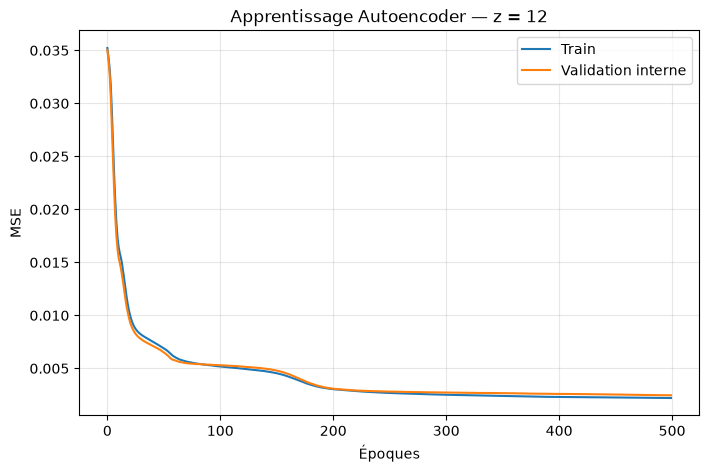

In [28]:
best_history = latent_histories[
    BEST_LATENT_DIM
]

fig = plt.figure(figsize=(8, 5))

plt.plot(
    best_history["loss"],
    label="Train"
)

plt.plot(
    best_history["val_loss"],
    label="Validation interne"
)

plt.xlabel("Époques")
plt.ylabel("MSE")
plt.title(
    f"Apprentissage Autoencoder — z = {BEST_LATENT_DIM}"
)

plt.legend()
plt.grid(alpha=0.3)

fig.savefig(
    FIGURES_DIR / "autoencoder_training_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

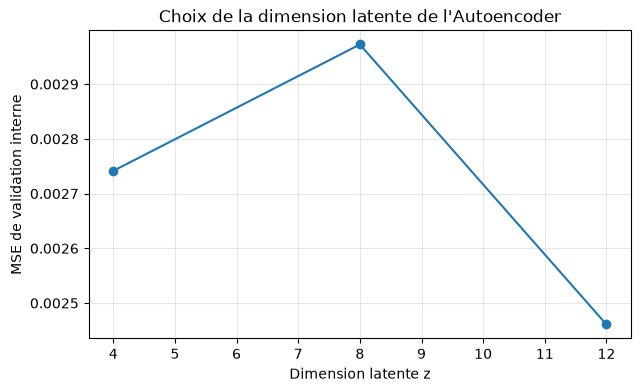

In [27]:
fig = plt.figure(figsize=(7, 4))

plt.plot(
    latent_results_df["Latent_Dim"],
    latent_results_df["Validation_MSE"],
    marker="o"
)

plt.xlabel("Dimension latente z")
plt.ylabel("MSE de validation interne")
plt.title(
    "Choix de la dimension latente de l'Autoencoder"
)

plt.grid(alpha=0.3)

fig.savefig(
    FIGURES_DIR / "autoencoder_latent_dimension_selection.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [26]:
best_row = latent_results_df.loc[
    latent_results_df["Validation_MSE"].idxmin()
]

BEST_LATENT_DIM = int(
    best_row["Latent_Dim"]
)

BEST_EPOCH = int(
    best_row["Best_Epoch"]
)

print("Meilleure dimension latente :", BEST_LATENT_DIM)
print("Meilleure époque :", BEST_EPOCH)
print(
    "Meilleure MSE validation :",
    best_row["Validation_MSE"]
)

Meilleure dimension latente : 12
Meilleure époque : 500
Meilleure MSE validation : 0.0024608271196484566


In [25]:
CANDIDATE_LATENT_DIMS = [4, 8, 12]

latent_results = []
latent_histories = {}

for latent_dim in CANDIDATE_LATENT_DIMS:

    print(f"\n===== Test z = {latent_dim} =====")

    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    encoder_tmp, decoder_tmp, autoencoder_tmp = build_autoencoder(
        latent_dim
    )

    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=40,
        restore_best_weights=True,
        min_delta=1e-6,
        verbose=0
    )

    history = autoencoder_tmp.fit(
        ae_train,
        ae_train,

        validation_data=(
            ae_val,
            ae_val
        ),

        epochs=500,
        batch_size=32,
        shuffle=True,

        callbacks=[
            early_stopping
        ],

        verbose=0
    )

    latent_histories[latent_dim] = history.history

    val_losses = np.array(
        history.history["val_loss"]
    )

    best_index = int(
        np.argmin(val_losses)
    )

    latent_results.append({
        "Latent_Dim": latent_dim,
        "Best_Epoch": best_index + 1,
        "Train_MSE": history.history["loss"][best_index],
        "Validation_MSE": val_losses[best_index],
        "Epochs_Run": len(val_losses)
    })


latent_results_df = pd.DataFrame(
    latent_results
)

display(latent_results_df)


===== Test z = 4 =====


===== Test z = 8 =====

===== Test z = 12 =====


,Latent_Dim,Best_Epoch,Train_MSE,Validation_MSE,Epochs_Run
0,4,499,0.002366,0.002741,500
1,8,500,0.002835,0.002972,500
2,12,500,0.002206,0.002461,500


In [24]:
def build_autoencoder(latent_dim, learning_rate=1e-3):

    # ---------- ENCODER ----------
    encoder_input = keras.Input(
        shape=(N_FEATURES,),
        name="transaction"
    )

    x = layers.Dense(
        20,
        activation="relu"
    )(encoder_input)

    x = layers.Dense(
        12,
        activation="relu"
    )(x)

    latent_output = layers.Dense(
        latent_dim,
        activation="relu",
        name="latent_space"
    )(x)

    encoder = keras.Model(
        encoder_input,
        latent_output,
        name=f"Encoder_z{latent_dim}"
    )

    # ---------- DECODER ----------
    decoder_input = keras.Input(
        shape=(latent_dim,),
        name="latent_input"
    )

    x = layers.Dense(
        12,
        activation="relu"
    )(decoder_input)

    x = layers.Dense(
        20,
        activation="relu"
    )(x)

    decoder_output = layers.Dense(
        N_FEATURES,
        activation="sigmoid",
        name="reconstruction"
    )(x)

    decoder = keras.Model(
        decoder_input,
        decoder_output,
        name=f"Decoder_z{latent_dim}"
    )

    # ---------- AUTOENCODER ----------
    autoencoder_input = keras.Input(
        shape=(N_FEATURES,),
        name="autoencoder_input"
    )

    z = encoder(autoencoder_input)
    reconstruction = decoder(z)

    autoencoder = keras.Model(
        autoencoder_input,
        reconstruction,
        name=f"Autoencoder_z{latent_dim}"
    )

    autoencoder.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="mse"
    )

    return encoder, decoder, autoencoder

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import joblib

SEED = 42

tf.keras.utils.set_random_seed(SEED)

ae_train, ae_val = train_test_split(
    fraud_array,
    test_size=0.20,
    random_state=SEED,
    shuffle=True
)

print("Fraudes AE Train :", ae_train.shape)
print("Fraudes AE Validation interne :", ae_val.shape)

Fraudes AE Train : (264, 30)
Fraudes AE Validation interne : (67, 30)


In [22]:
sample_before = fraud_array[:5]

reconstructed_before = autoencoder.predict(
    sample_before,
    verbose=0
)

print("Forme entrée :", sample_before.shape)
print("Forme reconstruction :", reconstructed_before.shape)

mse_before = np.mean(
    (sample_before - reconstructed_before) ** 2
)

print(
    "Erreur moyenne avant entraînement :",
    mse_before
)

Forme entrée : (5, 30)
Forme reconstruction : (5, 30)
Erreur moyenne avant entraînement : 0.037539184


In [21]:
autoencoder.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse"
)

In [20]:
autoencoder_input = keras.Input(
    shape=(N_FEATURES,),
    name="autoencoder_input"
)

z = encoder(autoencoder_input)

reconstructed = decoder(z)

autoencoder = keras.Model(
    autoencoder_input,
    reconstructed,
    name="FraudAutoencoder"
)

autoencoder.summary()

Model: "FraudAutoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ autoencoder_input (InputLayer)  │ (None, 30)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder (Functional)            │ (None, 8)              │           976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Decoder (Functional)            │ (None, 30)             │           998 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,974 (7.71 KB)

 Trainable params: 1,974 (7.71 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
decoder_input = keras.Input(
    shape=(LATENT_DIM,),
    name="latent_input"
)

x = layers.Dense(
    12,
    activation="relu"
)(decoder_input)

x = layers.Dense(
    20,
    activation="relu"
)(x)

decoder_output = layers.Dense(
    N_FEATURES,
    activation="sigmoid",
    name="reconstruction"
)(x)

decoder = keras.Model(
    decoder_input,
    decoder_output,
    name="Decoder"
)

decoder.summary()

Model: "Decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ latent_input (InputLayer)       │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 12)             │           108 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 20)             │           260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstruction (Dense)          │ (None, 30)             │           630 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 998 (3.90 KB)

 Trainable params: 998 (3.90 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
encoder_input = keras.Input(
    shape=(N_FEATURES,),
    name="transaction"
)

x = layers.Dense(
    20,
    activation="relu"
)(encoder_input)

x = layers.Dense(
    12,
    activation="relu"
)(x)

latent_output = layers.Dense(
    LATENT_DIM,
    activation="relu",
    name="latent_space"
)(x)

encoder = keras.Model(
    encoder_input,
    latent_output,
    name="Encoder"
)

encoder.summary()

Model: "Encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ transaction (InputLayer)        │ (None, 30)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 20)             │           620 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 12)             │           252 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_space (Dense)            │ (None, 8)              │           104 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 976 (3.81 KB)

 Trainable params: 976 (3.81 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
N_FEATURES = X_real_fraud.shape[1]
LATENT_DIM = 8

print("Dimensions d'entrée :", N_FEATURES)
print("Dimensions latentes :", LATENT_DIM)

Dimensions d'entrée : 30
Dimensions latentes : 8


## Représentation latente

Chaque fraude possède 30 caractéristiques.

L'Encoder compresse ces 30 caractéristiques dans une représentation
latente plus petite notée `z`.

Dans cette expérience :

- entrée : 30 caractéristiques ;
- espace latent : 8 dimensions ;
- sortie : reconstruction des 30 caractéristiques.

Ainsi :

30 → Encoder → 8 → Decoder → 30

In [16]:
fraud_array = X_real_fraud.to_numpy(
    dtype=np.float32
)

print("Forme :", fraud_array.shape)
print("Minimum :", fraud_array.min())
print("Maximum :", fraud_array.max())

Forme : (331, 30)
Minimum : 0.0
Maximum : 1.0


In [15]:
X_real_fraud = (
    X_train.loc[y_train == 1]
    .copy()
    .reset_index(drop=True)
)

print("Fraudes réelles utilisées :", X_real_fraud.shape)

Fraudes réelles utilisées : (331, 30)


In [11]:
X_train = pd.read_parquet(
    PROCESSED_DIR / "X_train.parquet"
)

y_train = pd.read_parquet(
    PROCESSED_DIR / "y_train.parquet"
).squeeze()

print("X_train :", X_train.shape)
print("y_train :", y_train.shape)

print("\nRépartition des classes :")
print(y_train.value_counts())

X_train : (198608, 30)
y_train : (198608,)

Répartition des classes :
Class
0    198277
1       331
Name: count, dtype: int64


In [12]:
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
SYNTHETIC_DIR = PROJECT_ROOT / "results" / "synthetic"
MODELS_DIR = PROJECT_ROOT / "models"

for directory in [
    FIGURES_DIR,
    METRICS_DIR,
    SYNTHETIC_DIR,
    MODELS_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

print("Projet :", PROJECT_ROOT)

Projet : c:\Users\MSI\Desktop\fraud_detection_memoire


In [13]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from scipy.spatial.distance import pdist
from scipy.stats import ks_2samp, wasserstein_distance

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow :", tf.__version__)

TensorFlow : 2.21.0


# 07 — Augmentation par Autoencoder

Objectifs :

1. entraîner un Autoencoder uniquement à partir des fraudes du Train ;
2. apprendre une représentation latente compacte des fraudes ;
3. créer de nouveaux points dans cet espace latent ;
4. décoder ces points afin de produire des fraudes synthétiques ;
5. évaluer leur intégrité, leur diversité, leur fidélité et leur proximité avec les fraudes réelles ;
6. construire un Train Autoencoder candidat pour la comparaison finale des méthodes d'augmentation.

Les ensembles Validation et Test restent strictement réels et ne sont jamais utilisés pour entraîner l'Autoencoder.